# VisionDrive — unchanged pretrained YOLO11n evaluation

## 1. Research objective

**Primary evaluation: PERSON only.** Pilot figure QA exposed the Open Images Stool/COCO chair taxonomy mismatch. The two-class pilot is exploratory. A fresh **400-image** person-only cohort excludes all previously inspected and previously inspected images. Its source-only selection, mapping and thresholds were frozen before fresh-cohort inference.

Measure original COCO-pretrained YOLO11n on real indoor images. **No training or fine-tuning occurs.** Results address person localization, not all obstacles, calibrated distance or physical collision avoidance.

Public data is external to this project but is **not proven independent of COCO pretraining**. No team camera recordings were supplied.

Run all cells using the evaluation environment from the repository README. Downloads are cached, checked and explicit. Expect original weights in `weights/laptop/yolo11n.pt`; run the setup script first. Outputs go to `outputs/evaluation/yolo11n/`.

## 2. Environment setup
The device is explicit. Use `DEVICE="cpu"` only when intentionally measuring CPU performance; never silently substitute it for CUDA.

In [1]:
from pathlib import Path
import os, sys, json
ROOT=Path.cwd().resolve()
if not (ROOT/'demo.py').exists() and (ROOT.parent/'demo.py').exists(): ROOT=ROOT.parent
assert (ROOT/'demo.py').exists(), "Run from repository root or notebooks/"
sys.path.insert(0,str(ROOT))
os.environ['YOLO_CONFIG_DIR']=str(ROOT/'.cache/ultralytics')
os.environ['YOLO_AUTOINSTALL']='false'
os.environ['USE_TF']='0'
os.environ['USE_FLAX']='0'
import torch, ultralytics, numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from IPython.display import display, Image, Markdown
from visiondrive.evaluation.data import acquire, validate, read_jsonl, digest, NAMES, COCO_NAMES, write_json
from visiondrive.evaluation.runner import load_config, environment, load_model, native_dataset, extract_native, predictions_and_benchmark, assemble_results, save_results
from visiondrive.evaluation.metrics import aggregate, bootstrap, conditions, match
from visiondrive.evaluation.report import exploration
DEVICE='0'
config=load_config(device=DEVICE)
dataset=ROOT/config['dataset']; output=ROOT/config['output']
output.mkdir(parents=True,exist_ok=True)
display(pd.Series(environment(config),name='environment'))

python                                                       3.13.5
os                                        Windows-11-10.0.26300-SP0
cpu               AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD
logical_cpus                                                     12
packages          {'torch': '2.11.0+cu128', 'torchvision': '0.26...
cuda_available                                                 True
cuda_version                                                   12.8
gpu                          NVIDIA GeForce RTX 3050 6GB Laptop GPU
device                                                            0
image_size                                                      640
batch                                                             1
half                                                          False
Name: environment, dtype: object

## 3. Dataset acquisition and validation
Restore the frozen per-image manifest from official Open Images public storage. Every photo records author, original page, download URL, CC BY 2.0 license, dimensions, SHA-256 and source split. Original annotations are CC BY 4.0.

The source selection uses Building-family `IsInside=1`, human-verified **person presence or absence**, and excludes target group-of, depiction, inside/unknown flags, label conflicts and ambiguous person hierarchy overlaps. No missing label is assumed negative. Person subtypes are propagated; coincident cross-source boxes are collapsed, while remaining ambiguous overlaps exclude the image. Source Chair is not complete for COCO chair because Stool is separate, so chair is not scored.

The frozen cohort contains **400 images (80 dev / 320 test)** and **923 person instances (191 dev / 732 test)**. Each partition is 75% person-positive and 25% verified negative, with one photo per photographer and no photographer shared across splits. Development/test preserve official source assignments. All earlier inspected cohort and baseline IDs are excluded. Source-only sampling used seed 20261017 before inference. This satisfies the initial 300–500 practical target without claiming it is a statistical minimum. SHA-256 and 64-bit dHash checks reject exact/likely near duplicates; photographer identity is a scene proxy, not proof of physical scene independence.

See `docs/dataset_card.md` for candidate comparisons, licensing, source CSV checksums, exclusion counts and pretraining uncertainty. No training split is created for unchanged YOLO; a required Ultralytics `train` YAML key aliases development and is never used.

In [2]:
records=acquire(dataset)
validation=validate(dataset)
assert validation['valid'], validation['errors']
assert validation['manifest_sha256']==config['dataset_manifest_sha256']
assert digest(dataset/'manifest.jsonl')==digest(ROOT/'data/public/indoor-evaluation-manifest.jsonl')
display(validation)
write_json(output/'dataset_validation.json',validation)

{'valid': True,
 'images': 400,
 'splits': {'dev': 80, 'test': 320},
 'instances': {'dev/person': 191, 'test/person': 732},
 'independent_group_proxy': 'Flickr photographer URL',
 'groups': 400,
 'manifest_sha256': '459a891423980dfcd723f59b0bf191944e0ac0488b7fb6264a7ca647ac436752',
 'errors': [],
 'warnings': ['Photographer grouping is a proxy; physical scene IDs are unavailable.',
  'COCO pretraining overlap is not ruled out by source split or hashing within this repository.',
  'Public photographs are not a low-mounted robot camera course; no metric depth or motion ground truth.']}

## 4. Dataset exploration
Counts are objects and images separately. Ground-truth sheets allow visual inspection; source protocol and structural checks do not constitute independent exhaustive reannotation.

Images: 400  | Source splits: {'validation': 80, 'test': 320}


,split,class,images,instances
0,dev,person,60,191
1,test,person,240,732


0    Photographer grouping is a proxy; physical sce...
1    COCO pretraining overlap is not ruled out by s...
2    Public photographs are not a low-mounted robot...
Name: limitations, dtype: str

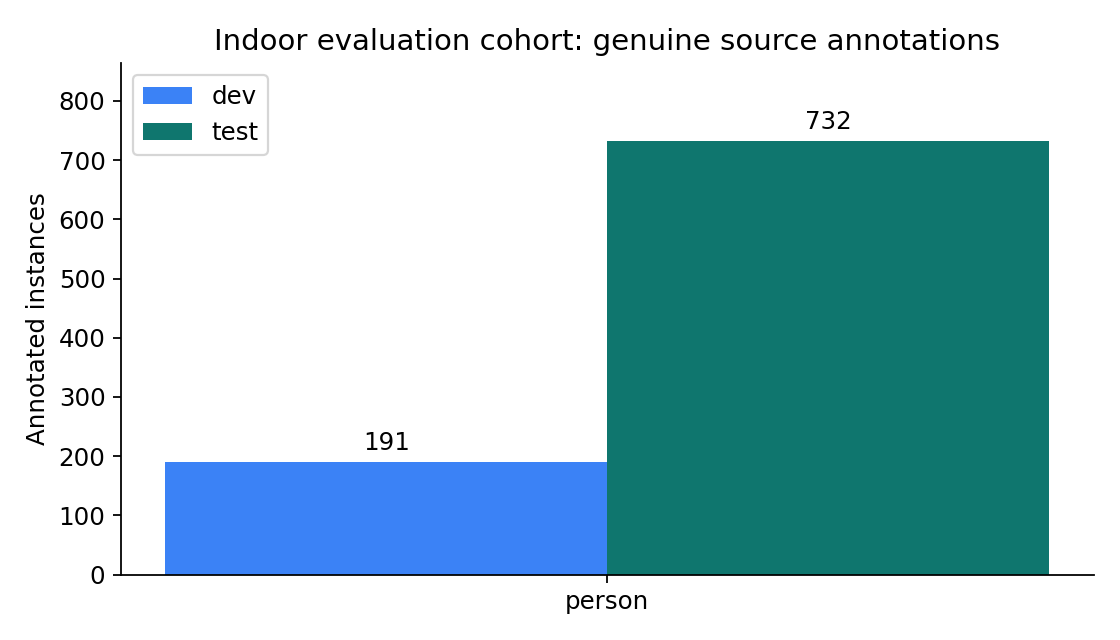

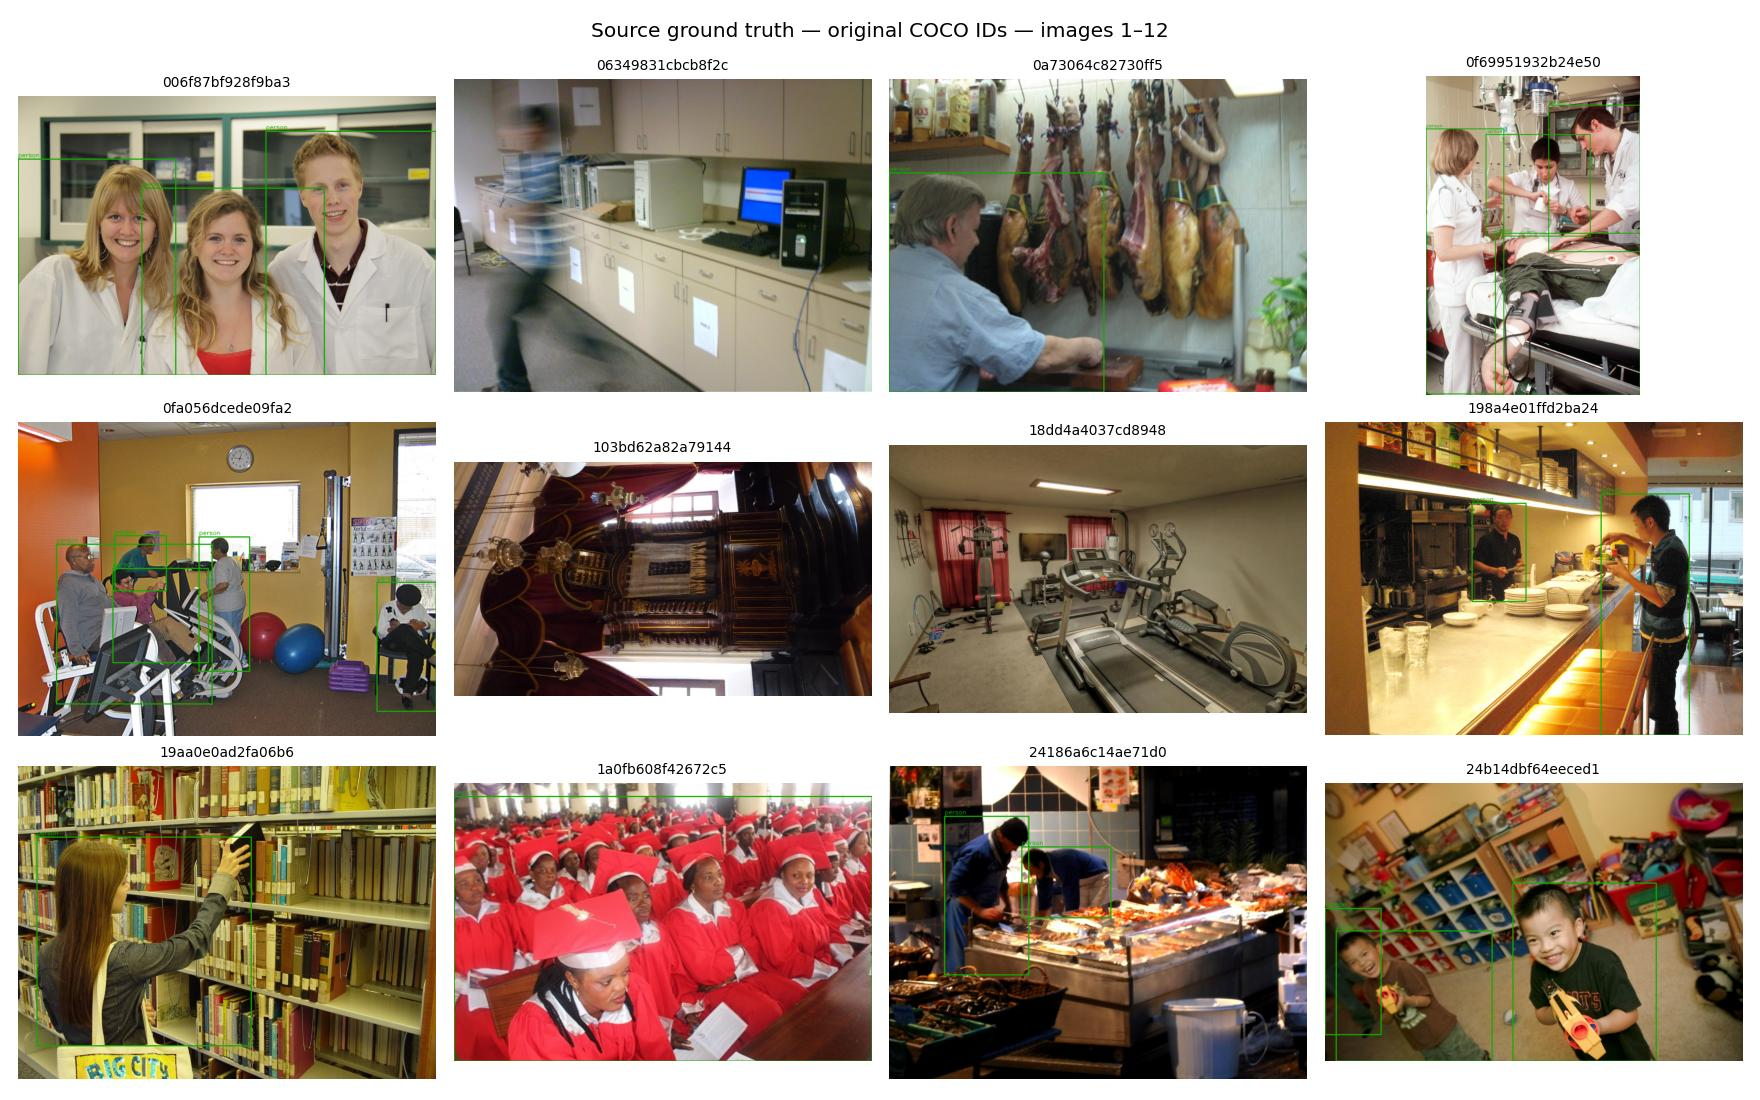

In [3]:
from collections import Counter
print('Images:',len(records),' | Source splits:',dict(Counter(r['source']['original_split'] for r in records)))
distribution=pd.DataFrame([{'split':s,'class':name,'images':sum(r['split']==s and any(o['label']==name for o in r['objects']) for r in records),
                            'instances':sum(o['label']==name for r in records if r['split']==s for o in r['objects'])}
                           for s in ['dev','test'] for name in config['class_names']])
display(distribution)
display(pd.Series(validation['warnings'],name='limitations'))
exploration(dataset,output)
display(Image(filename=str(output/'class_distribution.png')))
display(Image(filename=str(output/'ground_truth_review/sheet_01.jpg'),width=1100))

## 5. Load the original pretrained model
The original checkpoint and all 80 class names are checked. Only COCO ID 0 (person) is primary-scored; chair is excluded due to the Stool taxonomy mismatch; the live application retains all 80 categories.

### Upstream training data, benchmark and citation

YOLO11n was released by Ultralytics as an 80-class COCO-pretrained detector.
The official 640-pixel COCO val2017 benchmark reports **39.5% mAP50–95**,
2.6 million parameters and 6.5 GFLOPs. This differs from our person-only study.
COCO train2017 contains **118,287 images**; val2017 contains **5,000 images**.
Verified per-class image, instance and crowd counts are available in the
[80-class CSV](../data/public/coco2017-class-counts.csv) and
[source hashes/statistics](../data/public/coco2017-statistics.json).
Reproduce these with `python scripts/summarize_coco.py` after downloading
the official annotation ZIP as described in the
[README](../README.md#original-training-dataset-and-all-80-class-counts).

Cite **Jocher, G., & Qiu, J. (2024). Ultralytics YOLO11 (Version 11.0.0)
[Computer software]. https://github.com/ultralytics/ultralytics**.
The [official citation and benchmark](https://docs.ultralytics.com/models/yolo11/)
identify this as a software citation; no formal YOLO11 paper is supplied there.
See the [README BibTeX](../README.md#yolo11n-citation) and
[COCO paper](https://arxiv.org/abs/1405.0312) for paper references.


In [4]:
initial_sha=digest(ROOT/config['weights'])
assert initial_sha==config['weights_sha256']
model=load_model(config)
display({'checkpoint':config['weights'],'sha256':initial_sha,'parameters_before_fusion':sum(p.numel() for p in model.model.parameters()),
         'device':config['device'],'names':model.names})
assert model.names[0]=='person' and model.names[56]=='chair' and len(model.names)==80

{'checkpoint': 'weights/laptop/yolo11n.pt',
 'sha256': '0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1',
 'parameters_before_fusion': 2624080,
 'device': '0',
 'names': {0: 'person',
  1: 'bicycle',
  2: 'car',
  3: 'motorcycle',
  4: 'airplane',
  5: 'bus',
  6: 'train',
  7: 'truck',
  8: 'boat',
  9: 'traffic light',
  10: 'fire hydrant',
  11: 'stop sign',
  12: 'parking meter',
  13: 'bench',
  14: 'bird',
  15: 'cat',
  16: 'dog',
  17: 'horse',
  18: 'sheep',
  19: 'cow',
  20: 'elephant',
  21: 'bear',
  22: 'zebra',
  23: 'giraffe',
  24: 'backpack',
  25: 'umbrella',
  26: 'handbag',
  27: 'tie',
  28: 'suitcase',
  29: 'frisbee',
  30: 'skis',
  31: 'snowboard',
  32: 'sports ball',
  33: 'kite',
  34: 'baseball bat',
  35: 'baseball glove',
  36: 'skateboard',
  37: 'surfboard',
  38: 'tennis racket',
  39: 'bottle',
  40: 'wine glass',
  41: 'cup',
  42: 'fork',
  43: 'knife',
  44: 'spoon',
  45: 'bowl',
  46: 'banana',
  47: 'apple',
  48: 'sandwich',
 

## 6. Run native evaluation and genuine predictions
The dataset YAML preserves **all 80 original IDs**, and the filter uses `[0]`, not custom IDs `[0,1]`. Image lists come from the frozen manifest so excluded cached images cannot enter evaluation.

Native `model.val()` integrates AP over confidence at IoU .50:.05:.95. The displayed native P/R are its internally selected operating point and are **not** our fixed runtime P/R. Operational P/R/F1 below use .35 confidence and .50 IoU. NMS IoU=.70, max detections=300, square letterboxing to 640, FP32, batch=1. These settings were fixed before final test inference.

In [5]:
dataset_yaml=native_dataset(dataset,output)
native_metrics=model.val(data=str(dataset_yaml),split='test',imgsz=config['image_size'],batch=config['batch'],
    device=config['device'],half=config['half'],classes=config['class_ids'],
    conf=config['ap_confidence_floor'],iou=config['nms_iou'],max_det=config['max_detections'],
    plots=True,workers=0,rect=False,verbose=False,save_json=False,project=str(output),name='native',exist_ok=True)
native,curves=extract_native(native_metrics,config)
test_records=[r for r in records if r['split']=='test']
rows,benchmark=predictions_and_benchmark(model,config,dataset,test_records)
assert len(rows)==len(test_records)
assert digest(ROOT/config['weights'])==initial_sha

Ultralytics 8.3.112  Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients


val: Fast image access  (ping: 0.10.0 ms, read: 875.5613.6 MB/s, size: 182.7 KB)


val: Scanning <repo>\datasets\indoor-person-evaluation\labels\test...:   0%|          | 0/320 [00:00<?, ?it/s]

val: Scanning <repo>\datasets\indoor-person-evaluation\labels\test... 248 images, 64 backgrounds, 0 corrupt:  78%|███████▊  | 248/320 [00:00<00:00, 2457.75it/s]

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):  99%|█████████▉| 316/320 [00:08<00:00, 35.31it/s]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 320/320 [00:08<00:00, 38.95it/s]

                   all        320        732      0.769      0.656      0.721      0.509


Speed: 0.8ms preprocess, 10.2ms inference, 0.0ms loss, 2.1ms postprocess per image


Results saved to <repo>\outputs\evaluation\yolo11n\native


## 7. Detection metrics and statistical uncertainty
Predictions are confidence ordered, matched one-to-one to the highest-IoU available same-class ground truth at IoU≥.50. Duplicate predictions are false positives. Undefined ratios are assigned zero. Micro metrics pool TP/FP/FN. Macro F1 is the arithmetic mean of per-class F1. It is not the harmonic mean of macro precision and recall.

mAP@75 is the sixth threshold in `.50,.55,.60,.65,.70,.75,.80,.85,.90,.95`. Native AP matching differs from the fixed-point greedy matcher. The two protocols are reported separately. mAP is not classification accuracy.

95% percentile confidence intervals resample photographer groups 1,000 times. They do not resolve unknown physical scene relationships, sampling bias, or pretraining overlap; AP confidence intervals are not claimed.

In [6]:
fixed=aggregate(rows,config['confidence'],config['matching_iou'],config['class_ids'])
micro=fixed['micro']
assert micro['tp']+micro['fn']==sum(o['class_id'] in config['class_ids'] for r in rows for o in r['objects'])
assert np.isclose(micro['f1'],2*micro['tp']/(2*micro['tp']+micro['fp']+micro['fn']))
assert np.isclose(fixed['macro']['f1'],np.mean([v['f1'] for v in fixed['per_class'].values()]))
result=assemble_results(model,config,validation,native,rows,benchmark,initial_sha)
display(pd.Series({**micro,**{k:native[k] for k in ['map50','map75','map50_95']},'macro_f1':fixed['macro']['f1']}))
display(result['bootstrap'])

tp           468.000000
fp           123.000000
fn           264.000000
precision      0.791878
recall         0.639344
f1             0.707483
map50          0.721194
map75          0.540236
map50_95       0.509399
macro_f1       0.707483
dtype: float64

{'method': 'percentile bootstrap over photographer groups (scene proxy)',
 'groups': 320,
 'resamples': 1000,
 'seed': 20261017,
 'micro_95ci': {'precision': [0.7244933434145763, 0.8538407976827095],
  'recall': [0.5576386886770518, 0.7129589434785121],
  'f1': [0.6474937108586911, 0.7620732234549179]},
 'limitation': 'Does not account for unidentified cross-photographer scene overlap or COCO pretraining overlap; no AP CI.'}

## 8. Per-class results
Only person is primary-scored. Pilot chair scoring was excluded due to a Stool/Chair taxonomy mismatch. The final fresh person-only protocol was frozen before inference. Earlier chair numbers are exploratory, not reliable furniture performance.

In [7]:
per_class=pd.DataFrame(result['per_class']).T
display(per_class[['ground_truth','tp','fp','fn','precision','recall','f1','ap50','ap75','ap50_95']])
print('Other 79 COCO classes are not primary-scored, not scored as absent or failed.')

,ground_truth,tp,fp,fn,precision,recall,f1,ap50,ap75,ap50_95
person,732.0,468.0,123.0,264.0,0.791878,0.639344,0.707483,0.721194,0.540236,0.509399


Other 79 COCO classes are not primary-scored, not scored as absent or failed.


## 9. Diagnostic plots and prediction evidence
The fixed-point confusion matrices show same-class TP on the diagonal, misses in the final column and unmatched predictions in the final row. A wrong class contributes FP+FN; off-diagonal class substitution counts are not inferred. Normalization is by row, including the unmatched-prediction row. Native plots are retained separately under `native/`.

Example selection is transparent: three images with most misses, three with most false positives, and three deterministic initial examples. They illustrate observed failure modes and are not used to tune the model.

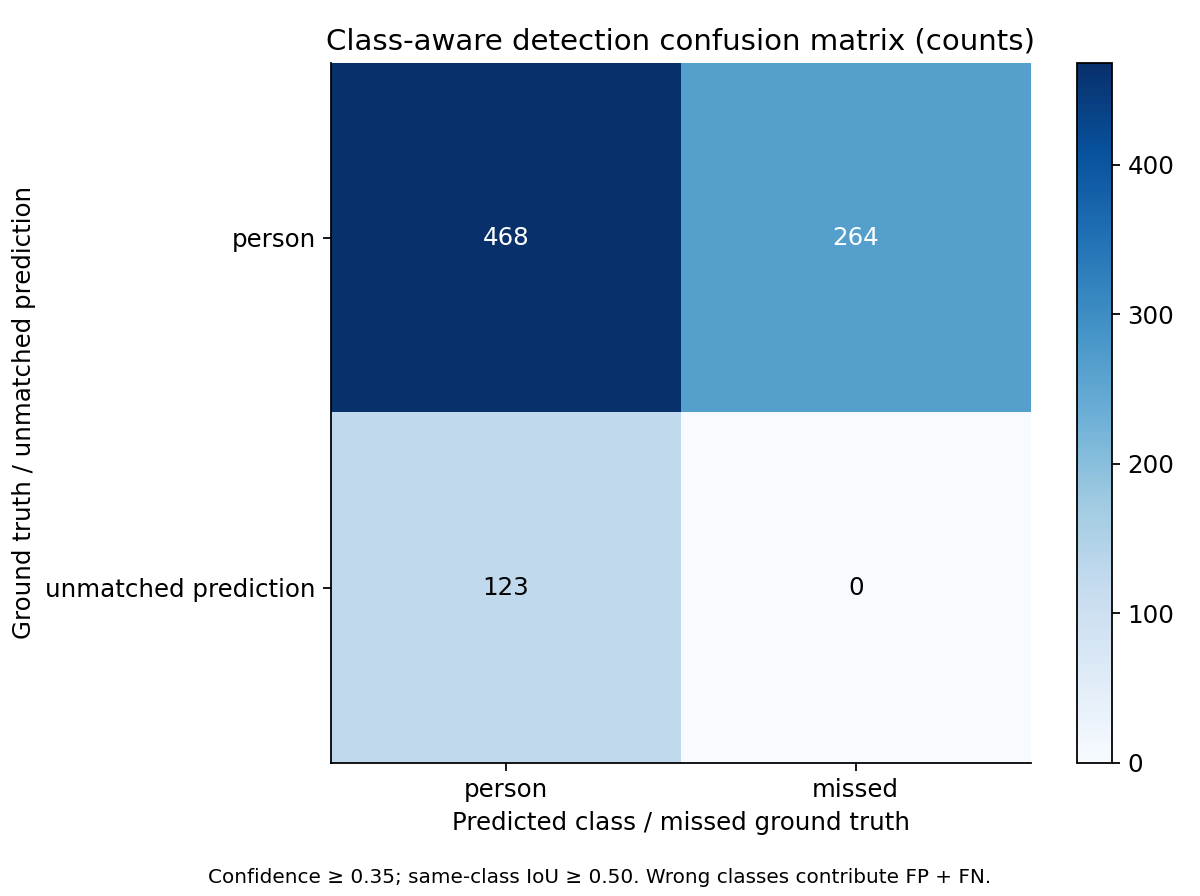

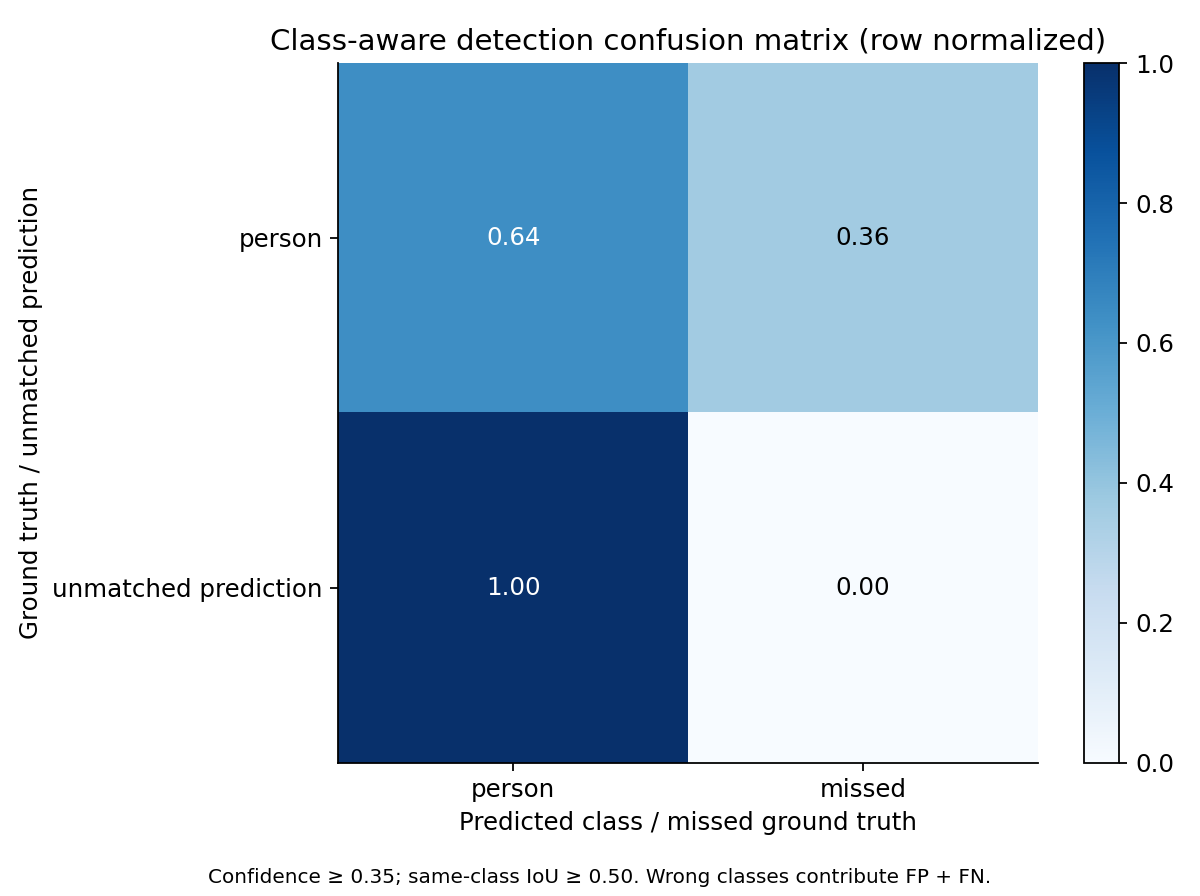

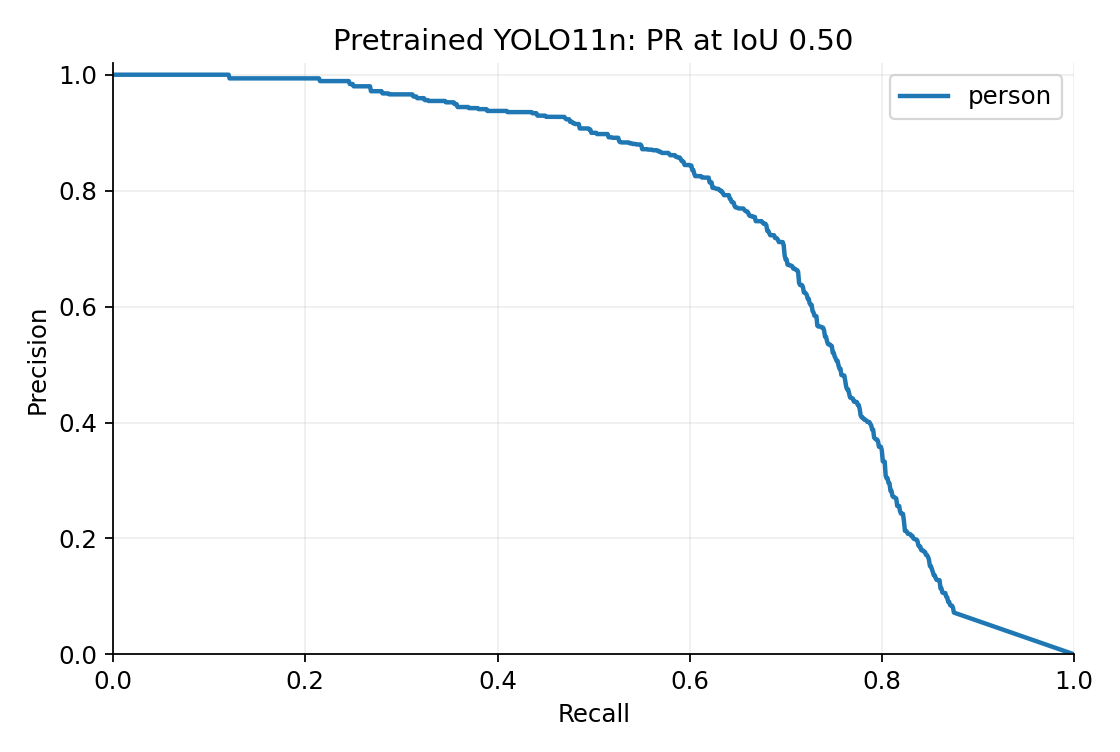

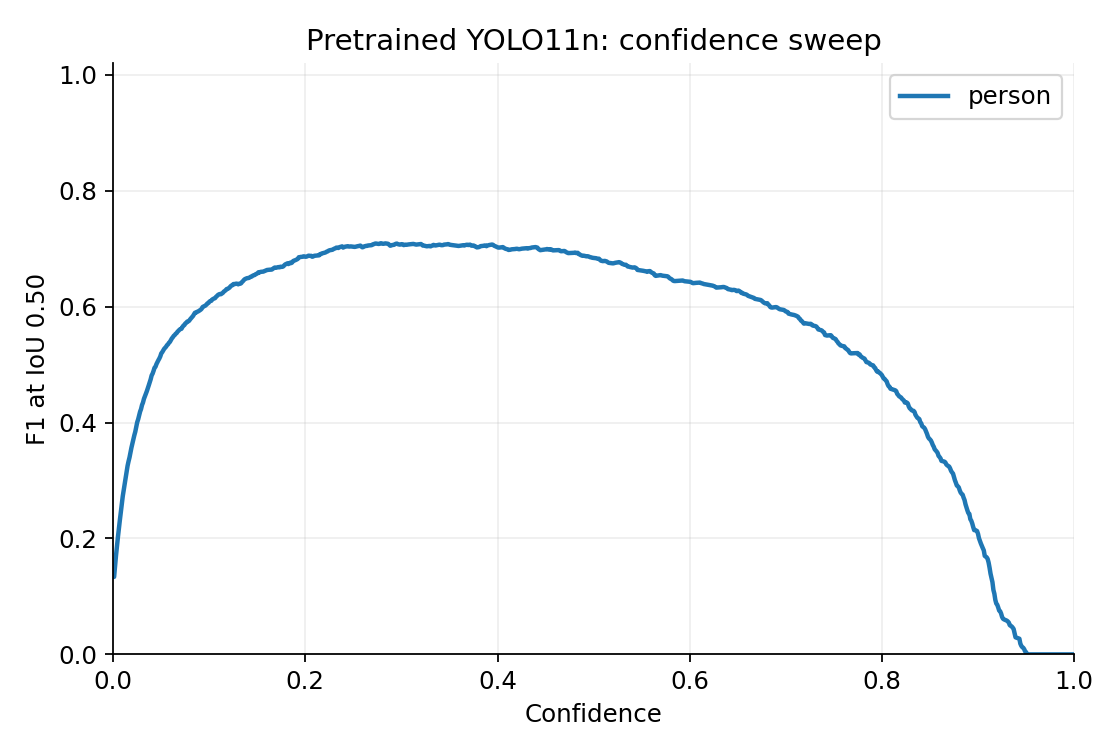

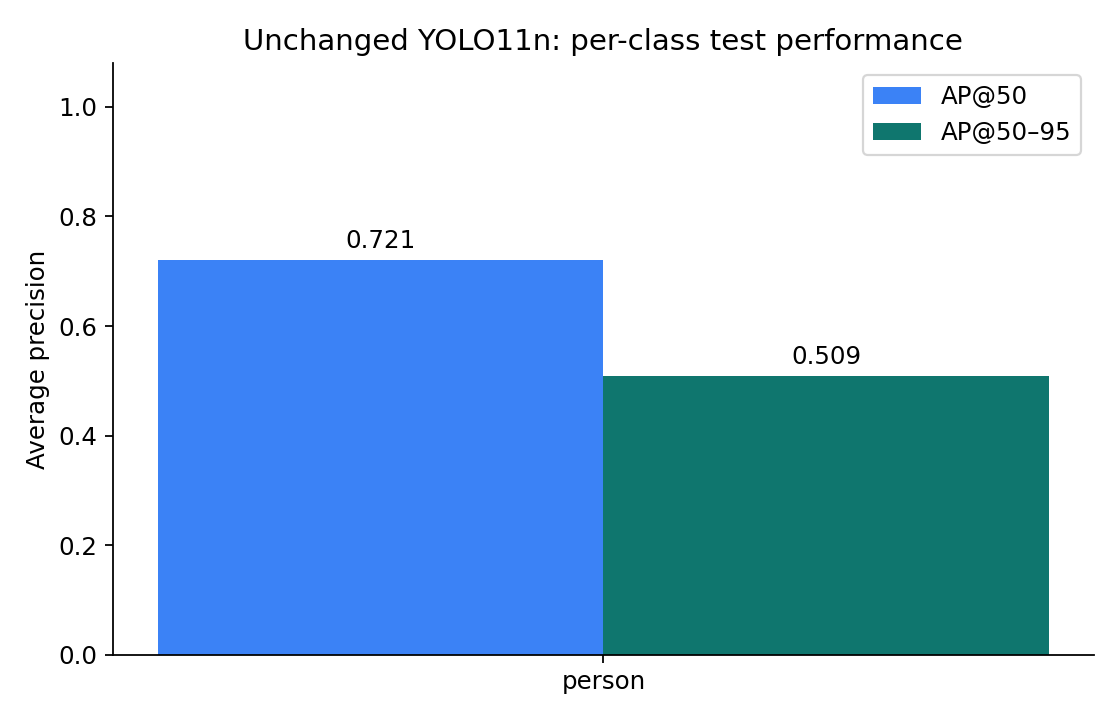

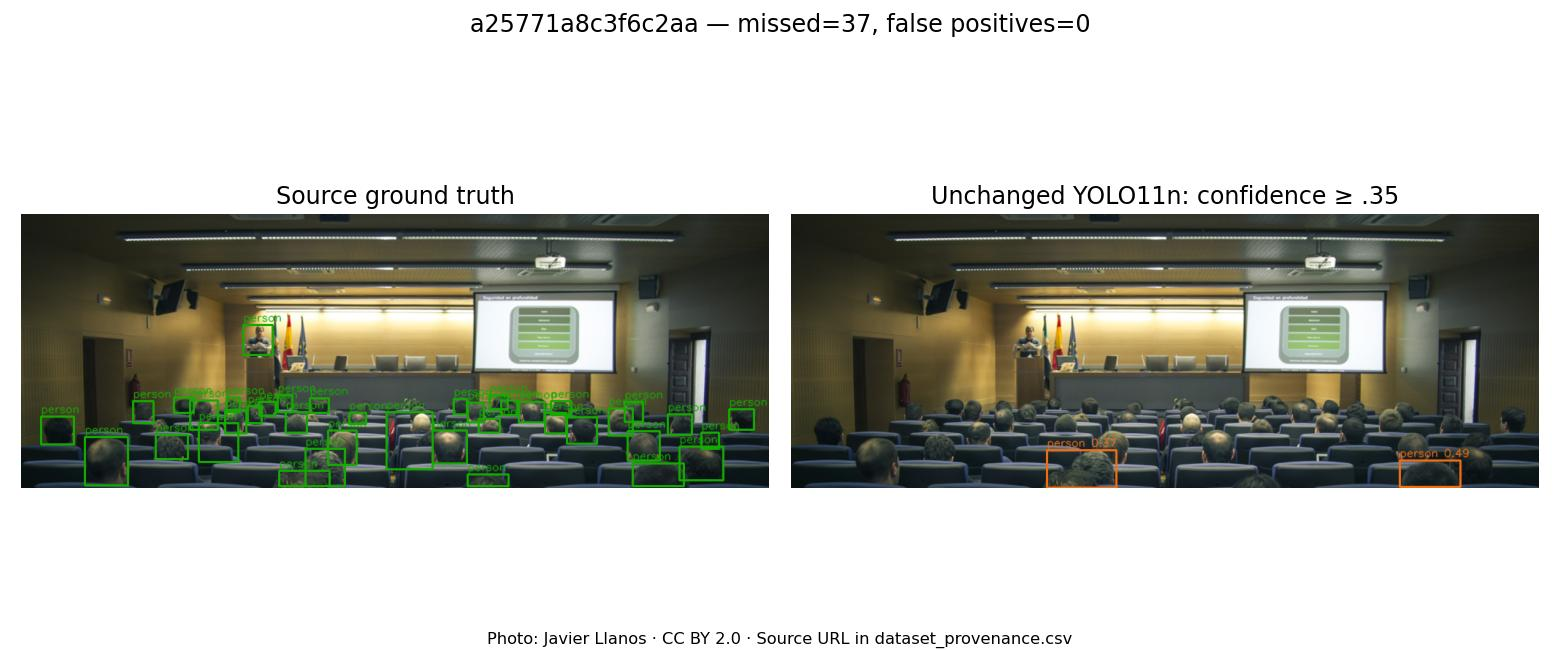

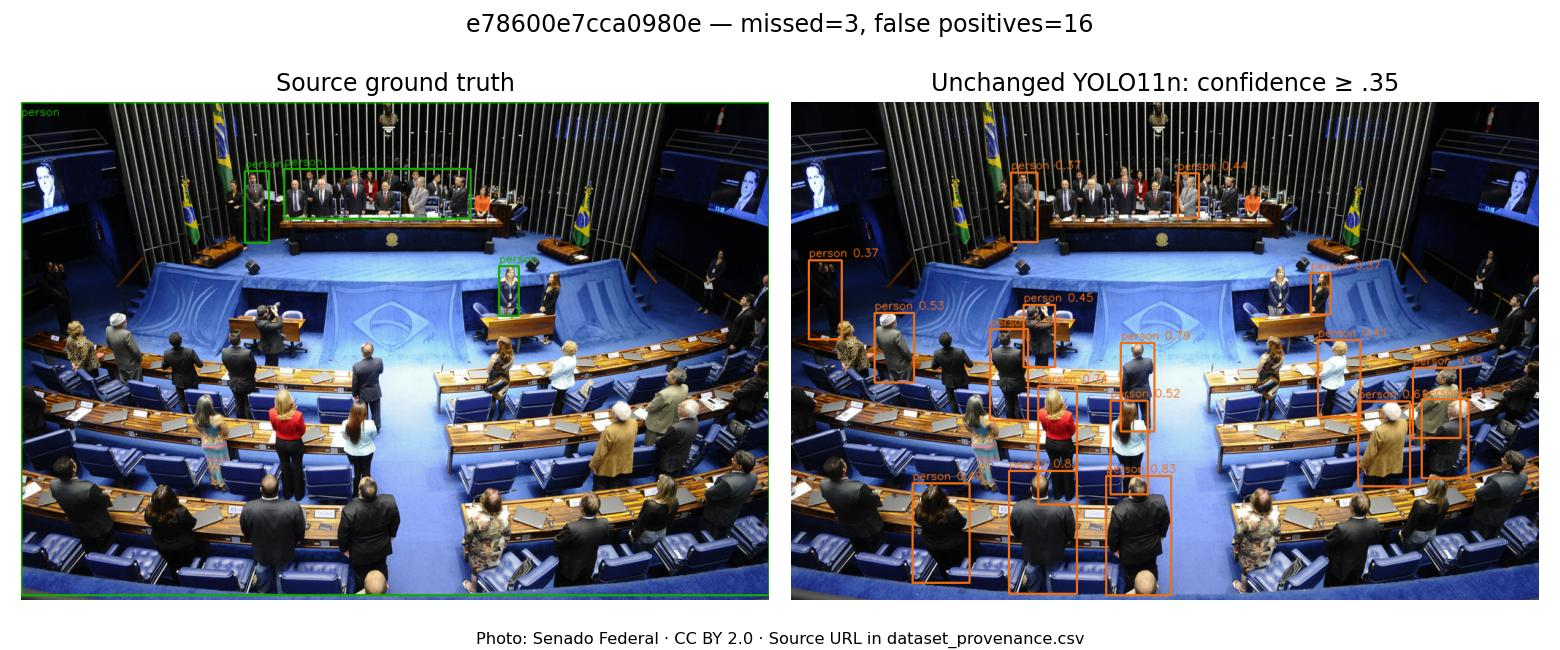

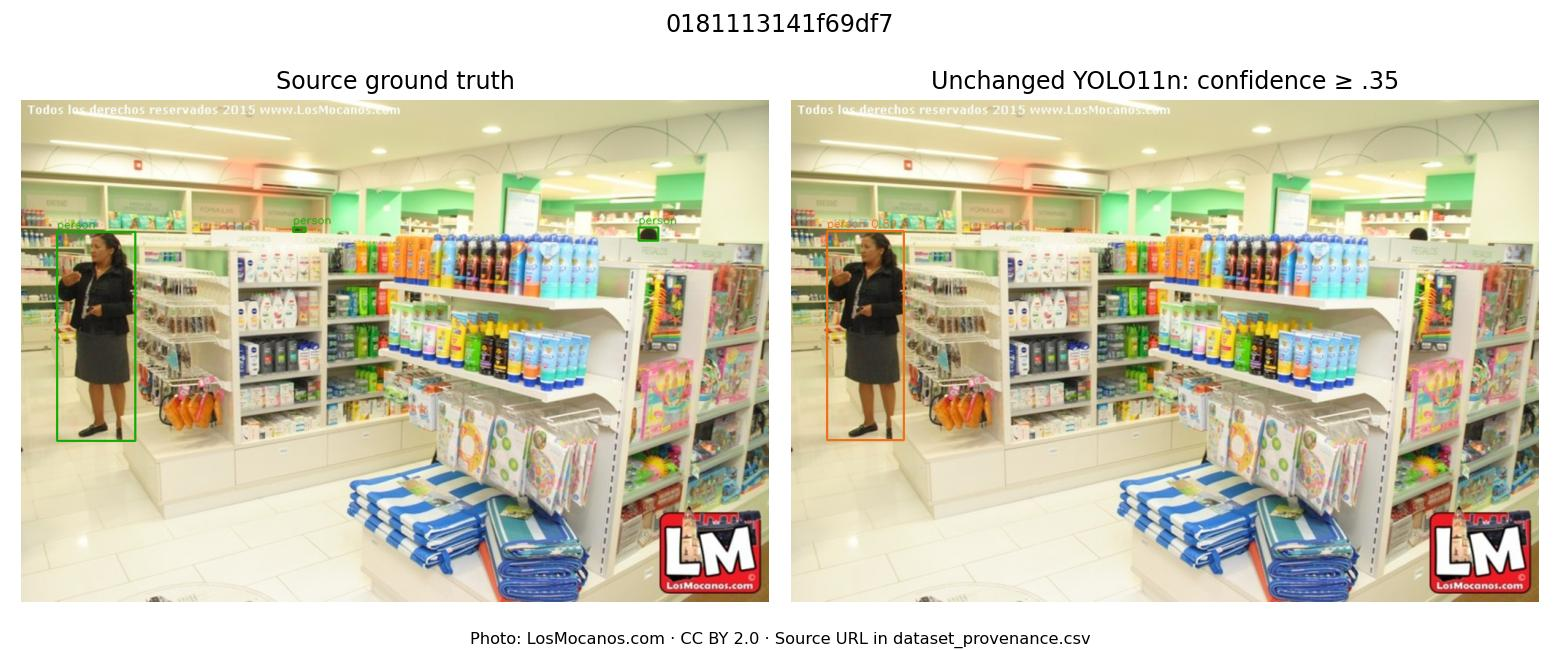

In [8]:
save_results(result,rows,curves,dataset,output)
for name in ['confusion_matrix.png','confusion_matrix_normalized.png','precision_recall_curve.png','f1_confidence_curve.png','per_class_performance.png']:
    display(Image(filename=str(output/name),width=750))
for name in ['missed_1.jpg','false_positive_1.jpg','example_1.jpg']:
    display(Image(filename=str(output/'prediction_examples'/name),width=1000))

## 10. Inference benchmarking
The prediction pass in Section 6 includes 10 warmups and synchronizes CUDA before and after each measured call. The first 100 test images (manifest order) provide latency samples; disk decode is outside timing. Ultralytics reports synchronized pre/network/post phases; external wall time includes Python overhead. Mean, median, population SD, p95, and 1000/mean FPS are recorded. Batch=1, FP32, 640×640.

**Model-only FPS excludes depth, camera, GUI, controller, UDP and motors.** Full perception/controller/render benchmarking is separate in `scripts/benchmark_system.py`; no physical navigation result follows from either speed measure.

In [9]:
timing=pd.DataFrame({phase:values for phase,values in benchmark.items() if isinstance(values,dict)}).T
display(timing)
display({k:v for k,v in benchmark.items() if not isinstance(v,dict)})

,mean_ms,median_ms,std_ms,p95_ms,fps_from_mean
preprocess,2.986381,2.90015,0.336195,3.64670,334.853456
inference,9.189527,8.43540,1.750200,12.88358,108.819529
postprocess,2.285963,1.83575,3.688565,2.69358,437.452400
predict_wall,14.922946,13.81625,4.067420,19.28401,67.010897


{'warmup_iterations': 10,
 'frames': 100,
 'batch': 1,
 'cuda_synchronized': True,
 'image_size': 640,
 'half': False,
 'includes': 'in-memory BGR to YOLO preprocessing, network, NMS; predict_wall adds Python overhead',
 'excludes': 'disk decode, camera, depth, display, controller and network; not complete-application FPS'}

## 11. Evidence-based error analysis
Source occlusion/truncation flags, source-pixel object area, image luminance and number of target instances provide observational condition recall. Small means area<32² source pixels, medium<96², large≥96². Dark means full-frame grayscale mean<70; many-target means ≥5 target objects. These bins are confounded and are not causal lighting or clutter experiments. Perspective and background complexity have no independent labels, so we do not invent their numerical effects.

In [10]:
condition_table=pd.DataFrame(result['condition_recall'])
display(condition_table)
misses=sorted([(sum(match(r,cid,config['confidence'],config['matching_iou'])['fn'] for cid in config['class_ids']),r['image_id']) for r in rows],reverse=True)
display(pd.DataFrame(misses[:5],columns=['false_negatives','source_image_id']))
print('Use the exported source-attributed examples to discuss specific misses; do not infer unmeasured physical distance.')

,condition,tp,ground_truth,recall
0,dark_mean_<70,25,41,0.609756
1,few_targets_<5,298,394,0.756345
2,large_>=96px,347,407,0.852580
3,many_targets_>=5,170,338,0.502959
4,medium_32-96px,121,243,0.497942
5,not_occluded,233,297,0.784512
6,not_truncated,307,529,0.580340
7,occluded,235,435,0.540230
8,other_luminance,443,691,0.641100
9,small_<32px,0,82,0.000000


,false_negatives,source_image_id
0,37,a25771a8c3f6c2aa
1,19,dfc78e19d1ba6658
2,9,83cf22aeb78c0852
3,8,fb214803c8d86e33
4,7,4a6a93acefe29e4a


Use the exported source-attributed examples to discuss specific misses; do not infer unmeasured physical distance.


## 12. Research interpretation and reproducibility record
The report below is generated from the measured predictions. Dataset/model/configuration/environment/source digests accompany it. No published benchmark is substituted for local measurements. Public-data results do not establish performance on our future car camera or prove independence from pretraining.

Depth metrics are pending valid aligned metric ground truth. Future camera data must keep complete recording sessions together, annotate every scored category (including verified empty images), use independent acceptable movement-action sets, and remain separate from public evaluation. See `docs/dataset_card.md`. All existing STOP/watchdog protections remain in the application.

In [11]:
assert result['weights_unchanged'] and digest(ROOT/config['weights'])==config['weights_sha256']
display(Markdown((output/'evaluation_report.md').read_text(encoding='utf-8')))
print('All outputs:',output.relative_to(ROOT).as_posix())
print('Checkpoint unchanged; no training executed.')

# Pretrained YOLO11n indoor evaluation

## 1. Objectives
Measure unchanged COCO-pretrained object recognition in real indoor photographs. This is not a collision-avoidance trial.

## 2. Dataset and sources
400 validated images: 80 development, 320 test. Original Open Images validation/test assignments are retained. Fresh Building-family interiors have verified person presence/absence; prior inspected and baseline images are excluded. There is one image per photographer and 75% person-positive / 25% verified person-negative images in each split. Only PERSON is primary-scored; chair is excluded because source Stool and Chair do not exhaustively cover the COCO chair concept.
Photos: individual authors, CC BY 2.0; annotations: Google/Open Images, CC BY 4.0. Attribution is in `dataset_provenance.csv`.
[Open Images annotation protocol](https://storage.googleapis.com/openimages/web/factsfigures_v7.html) · [Downloads and attributes](https://storage.googleapis.com/openimages/web/download_v7.html).

## 3. Model
Original YOLO11n COCO checkpoint SHA-256: `0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1`. No training or fine-tuning. Primary ID person=0; all 80 model names are retained. Parameters before fusion: 2,624,080; after inference fusion: 2,616,248.

## 4. Experimental setup
Input 640×640 letterboxed, FP32, batch 1. Device: NVIDIA GeForce RTX 3050 6GB Laptop GPU. Environment and source digests are recorded in JSON. Git: `8a6f52ad5d3b2f1edef7257b7b4c35e72da7780c`; dirty=True.

## 5. Ground truth
Human-verified person image labels and exhaustive source boxes are required. Whole images with target group-of, depiction, inside-target, unknown flags or label conflicts are excluded. Person subcategories are propagated, coincident cross-category boxes merged at IoU ≥ .95. Remaining cross-source person overlaps at IoU > .30 cause whole-image exclusion. This rule was frozen from pilot QA before fresh-cohort inference. Source protocol and visual spot checks are not independent exhaustive reannotation. No model-generated ground truth.

## 6. Definitions
Operational P/R/F1 use confidence ≥ .35 and greedy confidence-ordered same-class one-to-one IoU ≥ .50 matching. Undefined ratios are zero. Micro sums counts; macro F1 is the arithmetic mean of class F1, not the harmonic mean of macro P/R. AP is native Ultralytics integration at confidence floor .001, NMS IoU .70, max 300 detections. Only person is primary-scored, so mAP equals person AP. It is not classification accuracy.

## 7. Overall results
Micro precision 0.7919; recall 0.6393; F1 0.7075; TP=468, FP=123, FN=264.
mAP@50=0.7212; mAP@75=0.5402; mAP@50–95=0.5094. Macro F1=0.7075.
95% group-bootstrap intervals for micro P/R/F1: {'precision': [0.7244933434145763, 0.8538407976827095], 'recall': [0.5576386886770518, 0.7129589434785121], 'f1': [0.6474937108586911, 0.7620732234549179]}. Resampling unit: photographer (scene proxy), 320 test groups, 1,000 resamples. No AP interval claimed.

## 8. Per-class results
| Class | GT | TP | FP | FN | P | R | F1 | AP50 | AP75 | AP50–95 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| person | 732 | 468 | 123 | 264 | 0.792 | 0.639 | 0.707 | 0.721 | 0.540 | 0.509 |

## 9. Error analysis
Measured condition breakdown (recall; observational and confounded, not causal):
| Condition | TP / ground truth | Recall |
|---|---:|---:|
| dark_mean_<70 | 25/41 | 0.610 |
| few_targets_<5 | 298/394 | 0.756 |
| large_>=96px | 347/407 | 0.853 |
| many_targets_>=5 | 170/338 | 0.503 |
| medium_32-96px | 121/243 | 0.498 |
| not_occluded | 233/297 | 0.785 |
| not_truncated | 307/529 | 0.580 |
| occluded | 235/435 | 0.540 |
| other_luminance | 443/691 | 0.641 |
| small_<32px | 0/82 | 0.000 |
| truncated | 161/203 | 0.793 |

Miss and false-positive examples are exported in `prediction_examples/`. Object overlap/background complexity and perspective have no independent condition labels; the example sheets support qualitative review, not invented quantitative claims.

## 10. Computational performance
After 10 warmups, 100 in-memory frames: model inference mean 9.19 ms, median 8.44 ms, population SD 1.75 ms, model-only throughput 108.8 FPS.
Preprocessing 2.99 ms; postprocessing 2.29 ms; Python predict-call wall mean 14.92 ms (67.0 FPS). CUDA synchronization: True. Disk decode, capture, depth, display, UDP and motor execution excluded.

## 11. Threats to validity
The 400-image target is a practical sample, not proof of generalization. Selection is stratified to 75% person-positive images, so precision depends on this chosen prevalence. Only person is primary-scored. Pilot figure QA found a Chair/Stool taxonomy mismatch; the pilot is exploratory, and the corrected person-only protocol was frozen before inference on the fresh cohort. Neither thresholds nor image selection were optimized from final test scores. Public interior photos differ from a low-mounted car camera. Exact/near duplicates and shared photographers are controlled within the cohort, but physical scene identities and COCO pretraining overlap are unproven. Published COCO benchmarks are external references only.
Depth evaluation: pending: no metric depth ground truth in selected images. Camera evaluation: pending: no independent team recordings supplied.

## 12. Conclusions
These measurements describe pretrained person localization on this explicitly selected indoor cohort. They do not validate furniture recognition or all-obstacle detection. Missed people and false detections remain. Depth cues and safeguarded movement recommendations need separate reference measurements and physical trials before navigation performance can be claimed.


All outputs: outputs/evaluation/yolo11n
Checkpoint unchanged; no training executed.


## 13. Secondary benchmark: bottles and cups

This separate experiment scores **all 5,000 COCO val2017 images** for bottle
(YOLO 39 / COCO 44) and cup (YOLO 41 / COCO 47). Of these, 641 images contain
at least one target and 4,359 contain neither. The unchanged pretrained model
is evaluated; no training or threshold tuning occurs.

The manifest and configuration were frozen in commit `127dfbe` before inference.
This is a known upstream validation benchmark, **not independent unseen camera
data**. Keep these results separate from the fresh person-only study above.
Download the official `annotations_trainval2017.zip` and `val2017.zip` to
`data/raw/coco2017/` before running the cell. The cell runs real inference again
and overwrites only the supplementary benchmark outputs.

AP uses official pycocotools COCOeval (bbox, 101 recall points, IoU .50:.05:.95,
all areas, maxDets=100). P/R/F1 use confidence ≥ .35 and IoU ≥ .50 with COCO
crowd/ignore rules. FP32, batch 1, input 640, NMS .70, AP floor .001.
The pretrained checkpoint retains all 80 classes; only bottle/cup are scored.

[COCO source](https://cocodataset.org/#download) ·
[Frozen manifest and individual license metadata](../data/public/coco-objects-manifest.jsonl) ·
[Configuration](../config/coco-objects-evaluation.json) ·
[Methodology](../docs/dataset_card.md#secondary-bottle-and-cup-benchmark) ·
[Evaluation script](../scripts/evaluate_coco_objects.py)


Actual inference and official COCO scoring completed on 5000 images.
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Evaluation source commit: 127dfbec9e24c6680143a20d13817017bd24cd37
No training; unchanged weights: 0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1


,yolo_id,coco_category_id,tp,fp,fn,precision,recall,f1,ap50,ap75,ap50_95,ground_truth,crowd_regions,positive_images
bottle,39.0,44.0,327.0,93.0,686.0,0.778571,0.322804,0.456385,0.483205,0.357268,0.320609,1013.0,12.0,379.0
cup,41.0,47.0,354.0,145.0,541.0,0.709419,0.395531,0.507891,0.494816,0.384359,0.356074,895.0,4.0,390.0


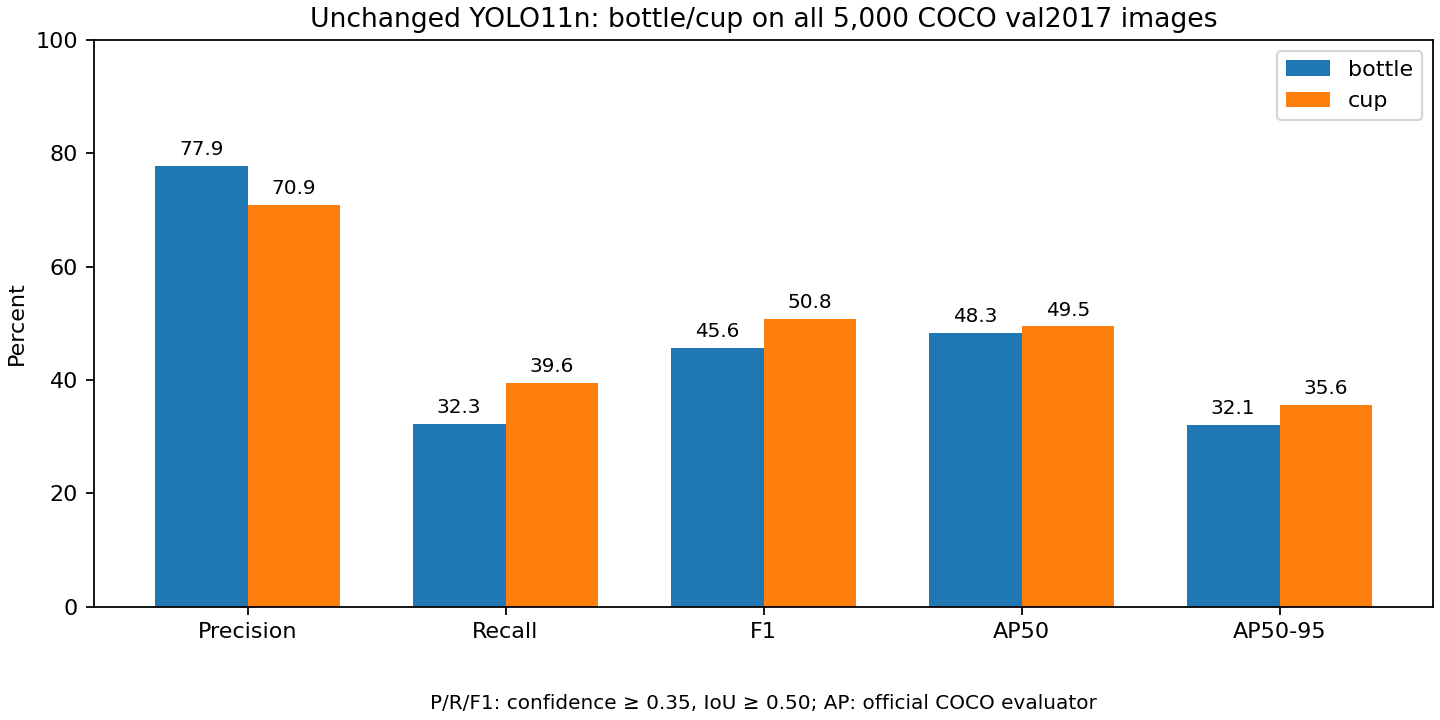

Limitation: known COCO validation benchmark; not independent unseen mini-car footage.


In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

root_objects = Path.cwd()
if not (root_objects / 'scripts').is_dir():
    root_objects = root_objects.parent
assert (root_objects / 'config/coco-objects-evaluation.json').exists()
objects_script = root_objects / 'scripts/evaluate_coco_objects.py'
objects_log = root_objects / '.cache/coco-objects-inference.log'
objects_log.parent.mkdir(parents=True, exist_ok=True)
objects_device = '0'  # Use 'cpu' explicitly if CUDA is unavailable.
with objects_log.open('w', encoding='utf-8') as log:
    for stage in ('prepare', 'evaluate'):
        subprocess.run([sys.executable, str(objects_script), '--stage', stage,
                        '--device', objects_device], cwd=root_objects,
                       stdout=log, stderr=subprocess.STDOUT, check=True)
objects_result = json.loads((root_objects / 'docs/results/yolo11n-coco-objects/metrics.json').read_text(encoding='utf-8'))
assert objects_result['images'] == 5000 and objects_result['weights_unchanged']
print('Actual inference and official COCO scoring completed on', objects_result['images'], 'images.')
print('GPU:', objects_result['environment']['gpu'])
print('Evaluation source commit:', objects_result['git_commit'])
print('No training; unchanged weights:', objects_result['weights_sha256'])
display(pd.DataFrame(objects_result['per_class']).T)
display(Image(filename=str(root_objects / 'assets/evaluation/coco-objects-performance.png')))
print('Limitation: known COCO validation benchmark; not independent unseen mini-car footage.')
